### Tests of the channels

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c, pi

from utils.utils import *
from components.ris import RIS
from components.antenna import Antenna
from channels.tx_ris_rx_channel import tx_ris_rx_channel

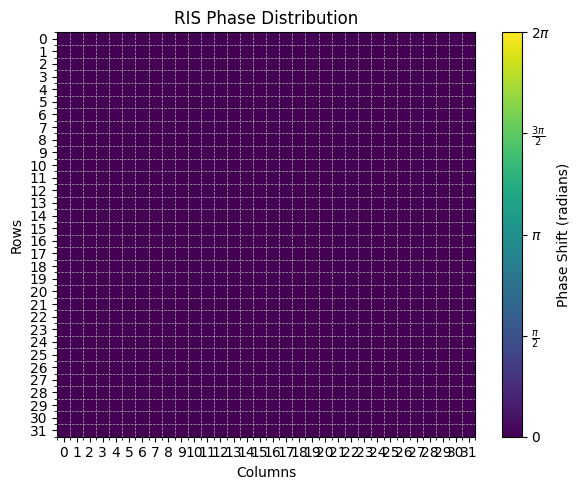

In [2]:
# Create RIS
f = 28e9
lam = c/f

ris = RIS(center=[0,0,0],boresight='z',Ncol=32,Nrow=32,delta_h=lam/2,delta_v=lam/2,dx=0.47*lam,dy=0.47*lam,fc=f,radiation_factor=1,phase_shifts_dict={"0": 0,"1": pi},att_dict={"0": 1,"1": 1})

ris.plot_phase_dist()

In [3]:
# Create antennas and channel
tx_pos = sph2cart([10.01,0,0])
rx_pos = sph2cart([11,180,30])

tx_antenna = Antenna(tx_pos,0)
rx_antenna = Antenna(rx_pos,0)

channel = tx_ris_rx_channel(tx_antenna=tx_antenna,rx_antenna=rx_antenna,ris=ris,optimizer='direct_disc')

ris2 = ris.copy()
channel_perf = tx_ris_rx_channel(tx_antenna=tx_antenna,rx_antenna=rx_antenna,ris=ris2, mode='perfect')

ris3 = ris.copy()
channel_maxbf = tx_ris_rx_channel(tx_antenna=tx_antenna,rx_antenna=rx_antenna,ris=ris3,optimizer='max_bf')


Previous state of perfect RIS:


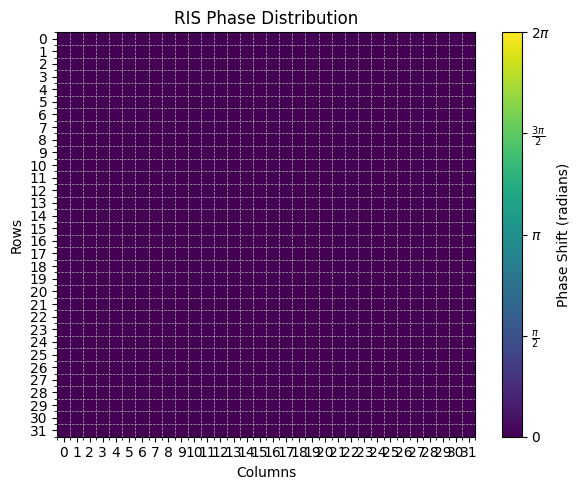

Optimized state of perfect RIS:


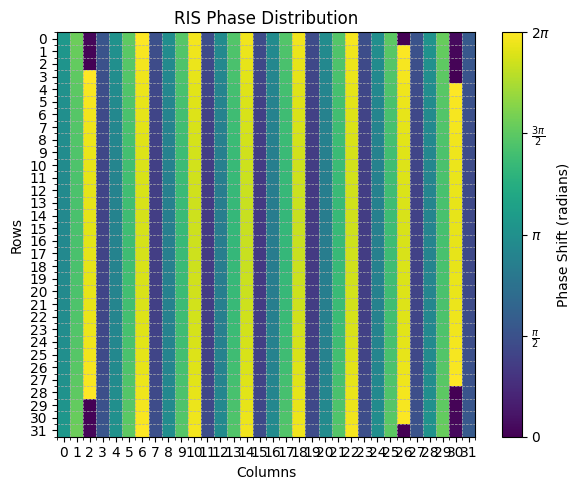

Previous state of normal RIS (direct dic. alg.):


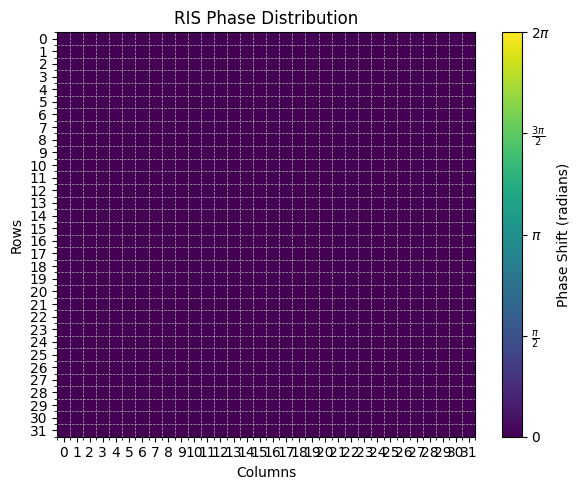

Optimized state of normal RIS (direct dic. alg.):


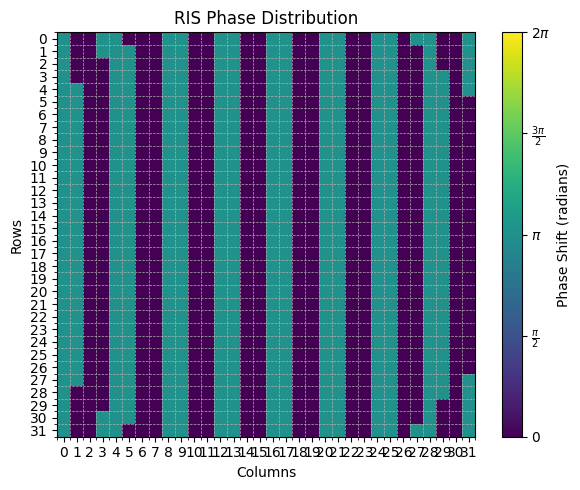

Previous state of normal RIS (max bf alg.):


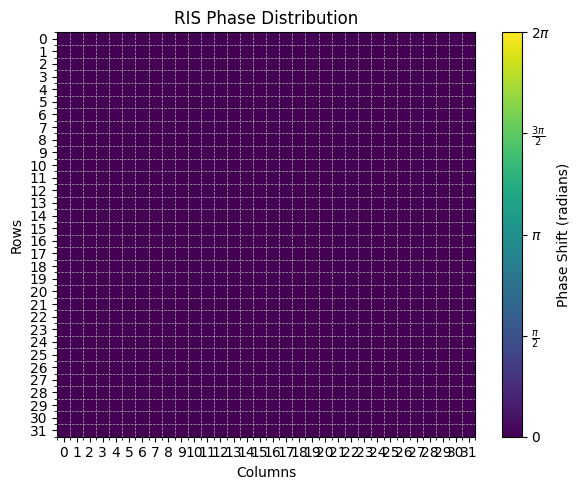

Optimum value of α: 2.100 rad
Optimized state of normal RIS (max bf alg.):


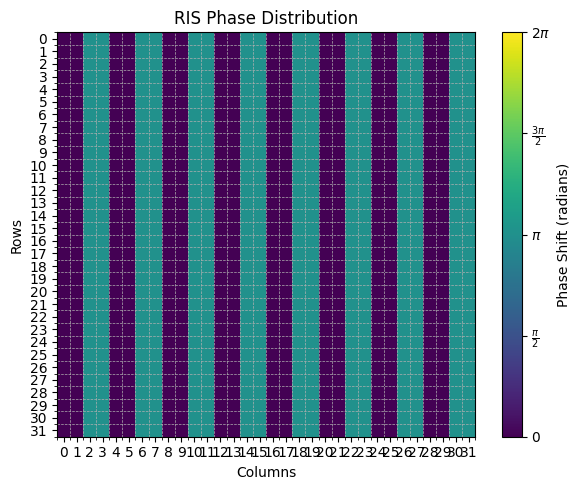

In [4]:
# Optimize channel and see the return
print("Previous state of perfect RIS:")
ris2.plot_phase_dist()

channel_perf.optimize()

print("Optimized state of perfect RIS:")
ris2.plot_phase_dist()

print("Previous state of normal RIS (direct dic. alg.):")
ris.plot_phase_dist()

channel.optimize()

print("Optimized state of normal RIS (direct dic. alg.):")
ris.plot_phase_dist()

print("Previous state of normal RIS (max bf alg.):")
ris3.plot_phase_dist()

channel_maxbf.optimize()

print("Optimized state of normal RIS (max bf alg.):")
ris3.plot_phase_dist()


Beamforming normalized at RX location with perfect shifts: 1.000


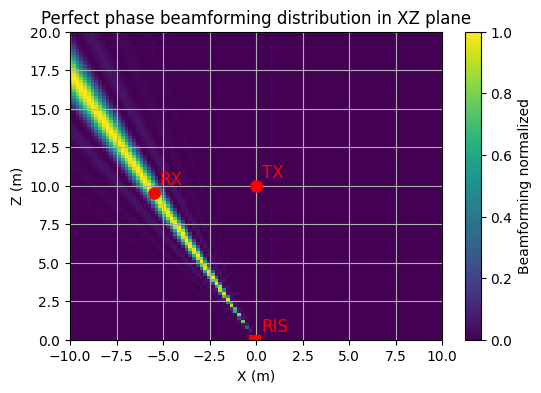

Beamforming normalized at RX location with direct discretization shifts: 0.454


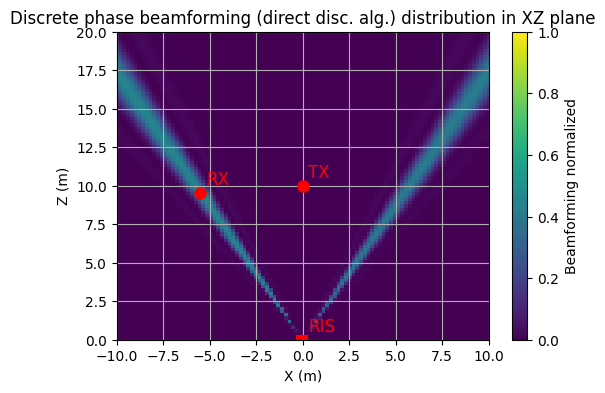

Beamforming normalized at RX location with max bf discretization shifts: 0.487


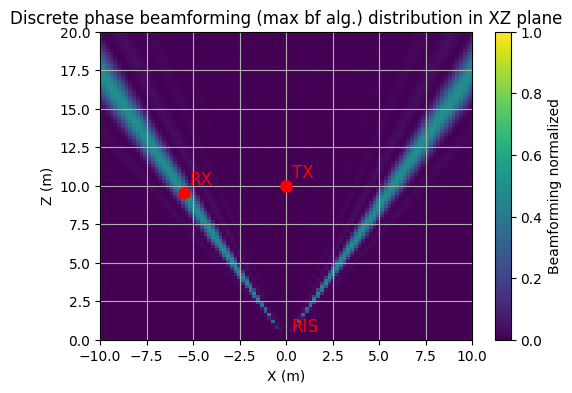

In [7]:
# Try phase beamforming function:

# Generate rx locations as a 2D map
xlim = [-10, 10]
zlim = [0, 20]
Nx = 100
Nz = 100

x = np.linspace(xlim[0], xlim[1], Nx)
z = np.linspace(zlim[0], zlim[1], Nz)
X, Z = np.meshgrid(x, z, indexing='ij')  # (Nx, Nz)
Y = np.zeros_like(X)

rx_points = np.stack([X, Y, Z], axis=-1)  # (Nx, Nz, 3)
rx_points = np.reshape(rx_points, (-1, 3))  # (Nx*Nz, 3)

# Calculate beamforming
bf_normal = channel.phase_bf_multrx(rx_points)
bf_perf = channel_perf.phase_bf_multrx(rx_points)
bf_normal_maxbf = channel_maxbf.phase_bf_multrx(rx_points)

maximum_bf = (ris.Nrow * ris.Ncol)**2
vmax = 1

print(f"Beamforming normalized at RX location with perfect shifts: {channel_perf.phase_bf_multrx(rx_pos[0])[0] / maximum_bf:.3f}")

# Plot 2D map
plt.figure(figsize=(6, 4))
pcm = plt.pcolormesh(X, Z, np.reshape(bf_perf,(Nx, Nz)) / maximum_bf, shading='auto', cmap='viridis', vmin=0, vmax=vmax)
plt.xlabel('X (m)')
plt.ylabel('Z (m)')
plt.title('Perfect phase beamforming distribution in XZ plane')
plt.colorbar(pcm, label='Beamforming normalized')
plt.xlim(xlim)
plt.ylim(zlim)
plt.grid(True)

plt.plot(channel.tx_antenna.position[0,0], channel.tx_antenna.position[0,2], 'ro', markersize=8)
plt.text(channel.tx_antenna.position[0,0] + 0.3, channel.tx_antenna.position[0,2] + 0.3, 'TX', color='red', fontsize=12, ha='left', va='bottom')

plt.plot(channel.rx_antenna.position[0,0], channel.rx_antenna.position[0,2], 'ro', markersize=8)
plt.text(channel.rx_antenna.position[0,0] + 0.3, channel.rx_antenna.position[0,2] + 0.3, 'RX', color='red', fontsize=12, ha='left', va='bottom')

plt.plot([channel.ris.positions[0,0,0], channel.ris.positions[0,3,0]], [0, 0], 'r-', linewidth=8)
plt.text(0.3, 0.3, 'RIS', color='red', fontsize=12, ha='left', va='bottom')
plt.show()

print(f"Beamforming normalized at RX location with direct discretization shifts: {channel.phase_bf_multrx(rx_pos[0])[0] / maximum_bf:.3f}")

# Plot 2D map
plt.figure(figsize=(6, 4))
pcm = plt.pcolormesh(X, Z, np.reshape(bf_normal,(Nx, Nz)) / maximum_bf, shading='auto', cmap='viridis', vmin=0, vmax=vmax)
plt.xlabel('X (m)')
plt.ylabel('Z (m)')
plt.title('Discrete phase beamforming (direct disc. alg.) distribution in XZ plane')
plt.colorbar(pcm, label='Beamforming normalized')
plt.xlim(xlim)
plt.ylim(zlim)
plt.grid(True)

plt.plot(channel.tx_antenna.position[0,0], channel.tx_antenna.position[0,2], 'ro', markersize=8)
plt.text(channel.tx_antenna.position[0,0] + 0.3, channel.tx_antenna.position[0,2] + 0.3, 'TX', color='red', fontsize=12, ha='left', va='bottom')

plt.plot(channel.rx_antenna.position[0,0], channel.rx_antenna.position[0,2], 'ro', markersize=8)
plt.text(channel.rx_antenna.position[0,0] + 0.3, channel.rx_antenna.position[0,2] + 0.3, 'RX', color='red', fontsize=12, ha='left', va='bottom')

plt.plot([channel.ris.positions[0,0,0], channel.ris.positions[0,3,0]], [0, 0], 'r-', linewidth=8)
plt.text(0.3, 0.3, 'RIS', color='red', fontsize=12, ha='left', va='bottom')
plt.show()

print(f"Beamforming normalized at RX location with max bf discretization shifts: {channel_maxbf.phase_bf_multrx(rx_pos[0])[0] / maximum_bf:.3f}")

# Plot 2D map
plt.figure(figsize=(6, 4))
pcm = plt.pcolormesh(X, Z, np.reshape(bf_normal_maxbf,(Nx, Nz)) / maximum_bf, shading='auto', cmap='viridis', vmin=0, vmax=vmax)
plt.xlabel('X (m)')
plt.ylabel('Z (m)')
plt.title('Discrete phase beamforming (max bf alg.) distribution in XZ plane')
plt.colorbar(pcm, label='Beamforming normalized')
plt.xlim(xlim)
plt.ylim(zlim)
plt.grid(True)

plt.plot(channel.tx_antenna.position[0,0], channel.tx_antenna.position[0,2], 'ro', markersize=8)
plt.text(channel.tx_antenna.position[0,0] + 0.3, channel.tx_antenna.position[0,2] + 0.3, 'TX', color='red', fontsize=12, ha='left', va='bottom')

plt.plot(channel.rx_antenna.position[0,0], channel.rx_antenna.position[0,2], 'ro', markersize=8)
plt.text(channel.rx_antenna.position[0,0] + 0.3, channel.rx_antenna.position[0,2] + 0.3, 'RX', color='red', fontsize=12, ha='left', va='bottom')

plt.plot([channel.ris.positions[0,0,0], channel.ris.positions[0,3,0]], [0, 0], 'r-', linewidth=8)
plt.text(0.3, 0.3, 'RIS', color='red', fontsize=12, ha='left', va='bottom')
plt.show()